# Задача 2: темы диалогов

## 0. План
- 1. Выбор подхожящих диалогов, согласно EDA.
- 2. Поиграть в кластеризацию
- 3. Читаем что объединилось + обзываем
- 4. Обучаем, Кросс-валидация
- 5. Тест
- 6. Разбор ошибок

## 1. Импорты и инициализация

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap
from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

import solution_utils as su
import bur_topics_utils as tu

pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
SEED = 42
BLUE, OCHRE = "#0072CE", "#C98A3C"

## 2. Загрузка данных (Поменяется при слиянии решений)

`dialogs` и `messages` собираются из `hw1_train.jsonl` функцией `build_frames` из `solution_utils`. `flags` — результат EDA (`dialog_flags.csv`): группы почти-копий (`group_id`), флаги шаблонов, пустых реплик и `use_topics`.

In [2]:
dialogs, messages, flags = tu.load_dialogs_and_flags()
print("dialogs:", dialogs.shape, " messages:", messages.shape, " flags:", flags.shape)

dialogs: (10000, 7)  messages: (133976, 10)  flags: (10000, 28)


## 3. Фильтры для задачи про темы

Берём правила из EDA для `flags`: 
- ~is_template` (не шаблонная первая реплика), 
- `~has_empty_message` (нет пустых реплик), 
- `use_topics` - диалоги чисто под вторую задачу.

И посмотрим сколько диалогов осталось

In [3]:
train_mask = tu.build_train_mask(flags)

In [4]:
display(tu.filter_funnel(flags))
print(f"в работе: {train_mask.sum()} из {len(flags)}")

,шаг,осталось
0,всего,10000
1,~is_template,10000
2,~has_empty_message,10000
3,use_topics,10000


в работе: 10000 из 10000


## 4. Подготовка текста диалогов

На рассмотрение будем брать весь текст пользователя. 

**Подготовка текста** (функция `preprocess_for_topics`):
1. каждая реплика обрезается до 1000 символов (огромные вставки кода мешают TF-IDF; в EDA 1% самых длинных реплик давал 8% всех символов);
2. нижний регистр, только слова из 3+ букв (числа и мусор вроде «aa», «abc» отбрасываются);
3. убираем стоп-слова
4. стемминг

**Замечание:**
Слова по типу "write", "use", "try" и остальные в этом духе - запишем в ручную в список стоп слов, т.к. тематически они ничего не значат, а встречаются очень часто,создавая шум.

In [5]:
user_text = tu.extract_user_text(messages)      # извлекаем реплики пользователя на диалог
prepared = user_text.map(tu.preprocess_for_topics)  # стоп-слова + стемминг
preview = tu.extract_preview(messages)  # исходный текст для чтения глазами

In [6]:
# пример для понимания
example_id = flags["dialog_id"].iloc[0]
print("исходный текст:\n", user_text[example_id][:300])
print("\nпосле обработки:\n", prepared[example_id][:300])

исходный текст:
 it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and into which it may result?
In the context of the equation “1+1=2+1+1=?,” if we want to explore the possibility of using a modulus to determine the result, we can consider different mod

после обработки:
 undefin modulus possibl concept result context equat explor possibl modulus determin result consid modulus valu affect equat modulus known remaind divid number denot symbol use remaind divis oper consid exampl modulus modulus evalu remaind divid number modulus modulus evalu remaind divid number modu


## 5. Разбиение train/test по группам "почти-копий"

Разбиваем на трейн и тест, не забывая что "братья" должны быть по одну сторону барикад, чтобы не палить модельке результаты.

In [7]:
train_ids, test_ids = tu.group_split(flags, train_mask, test_size=0.2, seed=SEED)
group_of = flags.set_index("dialog_id")["group_id"]

texts_train, texts_test = prepared.loc[train_ids], prepared.loc[test_ids]

In [8]:
print("train:", len(train_ids), " test:", len(test_ids))
print("общих групп у train и test:", len(set(group_of[train_ids]) & set(group_of[test_ids])))
print("диалогов train в группах размера > 1:", int(group_of[train_ids].duplicated(keep=False).sum()))


train: 8003  test: 1997
общих групп у train и test: 0
диалогов train в группах размера > 1: 247


## 6. Векторизация текста

**Логика.** TF-IDF даёт матрицу «диалоги × слова» с тысячами столбцов. Кластеризовать её напрямую плохо: расстояния между точками в таких пространствах почти одинаковы, а расчёт медленный. Поэтому:
1. **TF-IDF** (`sublinear_tf=True`: частота слова заменяется на `1 + ln(частота)`, чтобы повторы не доминировали);
2. **`TruncatedSVD`** сжимает до 100 столбцов — «тематических осей» (слова, которые встречаются вместе, оказываются на одной оси). Это то же сжатие, что PCA, но для разреженных матриц (обычный PCA вычитает среднее и сделал бы матрицу плотной);
3. **`Normalizer`** делает длину каждой строки равной 1: сравниваются направления, а не длины текстов.

**Замечание:** всё обучается **только на train** (`fit_transform`), а test лишь преобразуется (`transform`), чтобы информация о тесте не попала в признаки.


In [9]:
N_COMPONENTS = 100
lsa = make_pipeline(tu.make_tfidf(), TruncatedSVD(N_COMPONENTS, random_state=SEED), Normalizer(copy=False))
X_train = lsa.fit_transform(texts_train)
X_test = lsa.transform(texts_test)


In [10]:
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("словарь TF-IDF:", len(lsa[0].vocabulary_), "слов")

X_train: (8003, 100)  X_test: (1997, 100)
словарь TF-IDF: 12215 слов


## 7. Игры с кластеризацией

Два способа кластеризации, которые сравниваем:
- **KMeans на LSA:** `k` центров, каждый диалог относится к ближайшему.
- **UMAP + KMeans:** сначала UMAP сжимает 100-мерные векторы до 10 измерений, сохраняя «кто чей сосед», потом KMeans в сжатом пространстве. UMAP сам кластеры не находит, ему нужен второй шаг.

Чтобы выбрать подходящий `k`ссмотрим на две метрики:
- **inertia** — сумма квадратов расстояний до центров. Падает с ростом `k`. Ищем точку, после которой падение замедляется;
- **silhouette** — насколько диалог ближе к своему кластеру, чем к соседнему (от −1 до 1). Ищем `k`, где она велика.

**Замечание:** `silhouette_score(..., sample_size=3000)` считает силуэт по случайным 3000 точкам (на всех слишком долго). `n_init=5` — KMeans запускается 5 раз с разных стартов, берётся лучший результат.

In [11]:
reducer = umap.UMAP(n_neighbors=15, n_components=10, min_dist=0.0, random_state=SEED).fit(X_train)
U_train = reducer.embedding_    # координаты train после UMAP (10 измерений)

K_GRID = [4, 6, 8, 10, 12, 14, 16, 18, 20, 24]


def scan_k(Z):
    # Для каждого k: inertia и силуэт KMeans в пространстве Z.
    rows = []
    for k in K_GRID:
        km = KMeans(k, n_init=5, random_state=SEED).fit(Z)
        rows.append({"k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(Z, km.labels_, sample_size=3000, random_state=SEED)})
    return pd.DataFrame(rows).set_index("k")


scans = {"KMeans на LSA": scan_k(X_train), "UMAP + KMeans": scan_k(U_train)}

/home/pavel-ubunt/miniconda3/envs/ml/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


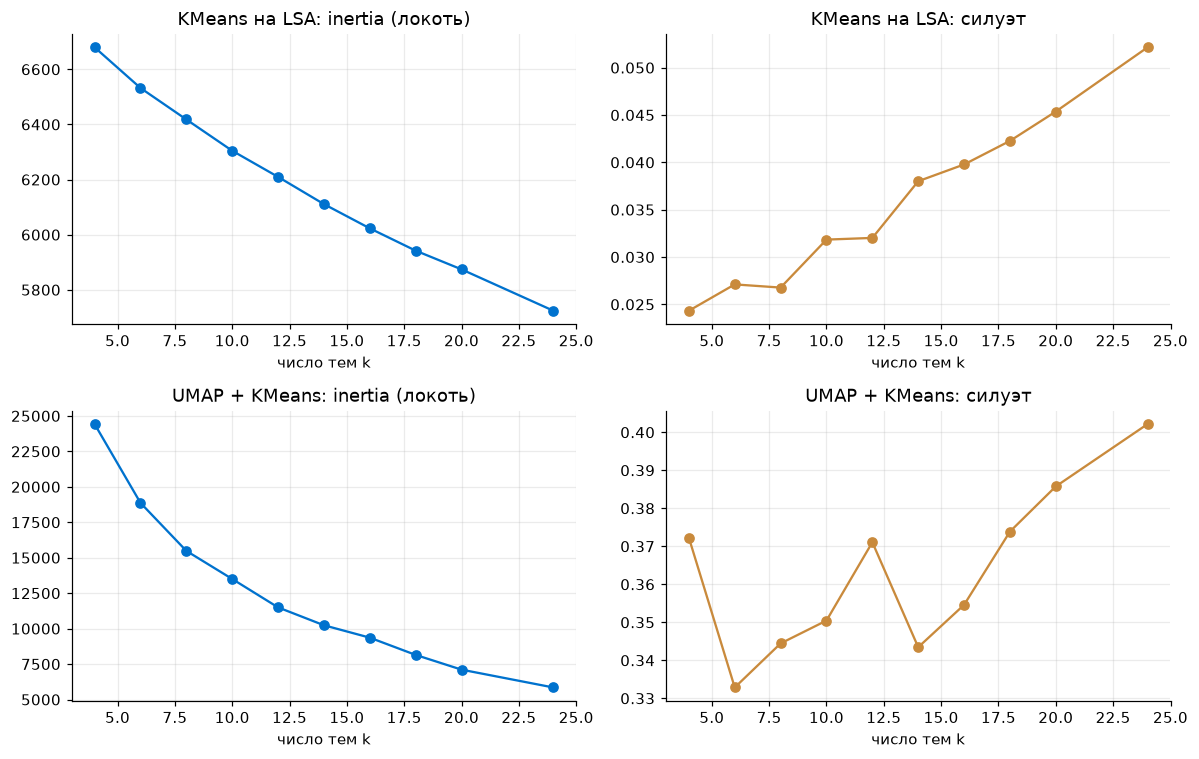

KMeans на LSA            UMAP + KMeans           
         inertia silhouette       inertia silhouette
k                                                   
4       6679.788      0.024     24423.168      0.372
6       6532.236      0.027     18865.719      0.333
8       6417.984      0.027     15480.458      0.344
10      6304.467      0.032     13499.018      0.350
12      6209.627      0.032     11496.262      0.371
14      6110.764      0.038     10235.770      0.343
16      6022.906      0.040      9360.860      0.355
18      5941.931      0.042      8144.596      0.374
20      5874.029      0.045      7105.550      0.386
24      5724.078      0.052      5849.886      0.402

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, (name, table) in enumerate(scans.items()):
    axes[row, 0].plot(table.index, table["inertia"], "o-", color=BLUE);  axes[row, 0].set_title(f"{name}: inertia (локоть)")
    axes[row, 1].plot(table.index, table["silhouette"], "o-", color=OCHRE); axes[row, 1].set_title(f"{name}: силуэт")
    for ax in axes[row]:
        ax.set_xlabel("число тем k")
plt.tight_layout()
plt.show()
display(pd.concat(scans, axis=1).round(3))

In [13]:
N_TOPICS = 12     # выбрали по графикам

## 8. Сравнение методов и итоговые кластеры

При выбранном `N_TOPICS` строим оба разбиения и сравниваем:
- **силуэт** и **индекс Дэвиса — Болдина** (минимальный == лучший), обе оценки считаем в одном пространстве LSA, чтобы они были сопоставимы.
- **доли самой маленькой и самой большой темы** сколько от общей выборки составляет минимальная и максимальная тема;
- **ARI между методами:** 1 — одно и то же разбиение, около 0 — совсем разные.

In [14]:
km_lsa = KMeans(N_TOPICS, n_init=10, random_state=SEED).fit(X_train)
km_umap = KMeans(N_TOPICS, n_init=10, random_state=SEED).fit(U_train)
partitions = {"KMeans на LSA": km_lsa.labels_, "UMAP + KMeans": km_umap.labels_}

rows = {}
for name, labels in partitions.items():
    shares = np.bincount(labels) / len(labels)
    rows[name] = {"силуэт": silhouette_score(X_train, labels, sample_size=3000, random_state=SEED),
                  "Дэвис — Болдин": davies_bouldin_score(X_train, labels),
                  "min доля темы": shares.min(), "max доля темы": shares.max()}


In [15]:
display(pd.DataFrame(rows).T.round(3))
print("ARI между методами:", round(adjusted_rand_score(*partitions.values()), 3))

,силуэт,Дэвис — Болдин,min доля темы,max доля темы
KMeans на LSA,0.036,4.242,0.029,0.204
UMAP + KMeans,0.030,4.523,0.013,0.199


ARI между методами: 0.296


### Назад дороги нет, пора сделать выбор

In [16]:
METHOD = "KMeans на LSA"      # "KMeans на LSA" или "UMAP + KMeans"; тупо по метрикам

labels_train = partitions[METHOD]
if METHOD == "KMeans на LSA":
    labels_test = km_lsa.predict(X_test)
else:
    labels_test = km_umap.predict(reducer.transform(X_test))       # новые точки сначала проводим через UMAP

In [17]:
print("метод:", METHOD, "| диалогов по темам в train:", np.bincount(labels_train).tolist())

метод: KMeans на LSA | диалогов по темам в train: [1633, 849, 448, 240, 354, 414, 861, 912, 522, 610, 924, 236]


## 9. Читаем кластеры и называем темы

Для каждого кластера печатаем **долю**, **характерные слова** (где средний TF-IDF в кластере больше всего превышает средний вне него) и **типичные диалоги** (ближайшие к центру кластера - исходный текст первых реплик). По ним мы и даём названия в `TOPIC_NAMES`.

`|` - разделитель между репликами

In [18]:
terms = tu.distinctive_terms(texts_train, labels_train, n_terms=13) # 13 характерных слов
reps = tu.representatives(X_train, labels_train, n=5) # 5 типичных диалогов
preview_train = preview.loc[train_ids].to_numpy()

for c in range(N_TOPICS):
    print(f"━━ кластер {c} | {np.mean(labels_train == c):.1%} диалогов")
    print("   слова:", ", ".join(terms[c]))
    for i in reps[c]:
        print("   •", preview_train[i][:170])

━━ кластер 0 | 20.4% диалогов
   слова: answer, gpt, book, mean, doe, short, sentenc, song, prompt, generat, name, youtub, exampl
   • Students will choose ONE of four novels to read independently.  The options include:  The Break  – Katherena V | “The man shifted, his chair squeaking as he did so, and p
   • I would like to make short 5-10 minute activities which can be used to teach English to Japanese middle school | Thank you I'll get to your response shortly, I forgot to 
   • I need to create interactive AI chat that using simplifiest english and popular tasks such as calculation/algo | No, it can not be challeging becouse I already have my ow
   • ""SGD : A Study on Self-Generated Dataset creation method for Direct Preference Optimization (DPO) Learning Th | So the model is inadvertently creating or generating the 
   • Please give me examples of phrases or full sentences to use when asked a question that is not within my expert | Thank you. Please give me a clear explanation of

In [19]:
TOPIC_NAMES = {
    0:  "Общие задания творческого направления",
    1:  "Ролевые игры",
    2:  "История и политика",
    3:  "Excel и VBA",
    4:  "Спорт",
    5:  "Фанфики",
    6:  "Код",
    7:  "Учебный вайб-кодинг",
    8:  "Научная деятельность с естественными науками",
    9:  "Менеджмент и бизнес",
    10: "Как устроиться в конторку",
    11: "Перевод текстов"
}
TOPIC_DESCRIPTIONS = {
    "Общие задания творческого направления": "Запросы «общего» характера — задания по литературе, короткие упражнения, промпты для GPT, примеры и определения.",
    "Ролевые игры": "Задания по типу 'подставь себя на его место - твои действия...', 'напиши письммо от лица...'",
    "История и политика": "Запросы про исторические события, альтернативную историю, политические системы и государственное устройство. Часто с просьбой 'написать сценарий' или 'создать лор'",
    "Excel и VBA": " Работа с таблицами в Excel: написание VBA-скриптов, обработка диапазонов, отладка ошибок",
    "Спорт": "Обсуждение видеоигр, спортивных матчей, RPG-механик, чемпионатов. Смешаны игровые запросы и спортивные события",
    "Фанфики": "Запросы про написание историй, разработку персонажей, сцен и диалогов. Рассуждения про алтернативные ветки",
    "Код": "Общие вопросы по программированию: написание кода, отладка ошибок, работа с файлами, сетью, базами данных. Языки разные — Python, C#, JS",
    "Учебный вайб-кодинг": "Учебные задачки на программирование. В этом и отличие от темы 'Код'",
    "Научная деятельность с естественными науками": "Запросы по химии, физике, материаловедению. Часто с просьбой отредактировать или написать академический текст",
    "Менеджмент и бизнес": "Запросы про рынки, акции, инвестиции, новости компаний. Часты переводы или краткие сожеражания финансовых новостей",
    "Как устроиться в конторку": "Запросы на перефразирования, подбор качесвт в резюме, поиск компаний и т.д.",
    "Перевод текстов": "Запросы по переводу текстов различных"
}

name_of = {c: TOPIC_NAMES.get(c, f"тема_{c:02d}: " + ", ".join(terms[c][:3])) for c in range(N_TOPICS)}
y_train = np.array([name_of[c] for c in labels_train], dtype=object)
y_test = np.array([name_of[c] for c in labels_test], dtype=object)

topic_table = pd.DataFrame({
    "название": list(pd.Series(y_train).value_counts().index),
    "доля": pd.Series(y_train).value_counts(normalize=True).round(3).to_numpy(),
})
topic_table["описание"] = topic_table["название"].map(TOPIC_DESCRIPTIONS).fillna("")
topic_table["слова"] = topic_table["название"].map({name_of[c]: ", ".join(terms[c][:8]) for c in range(N_TOPICS)})
topic_table["пример"] = topic_table["название"].map(
    {name: preview_train[np.flatnonzero(y_train == name)[0]][:100] for name in topic_table["название"]})
print("тем:", len(topic_table))
display(topic_table)

тем: 12


,название,доля,описание,слова,пример
0,Общие задания творческого направления,0.204,"Запросы «общего» характера — задания по литературе, короткие упражнения, промпты для GPT, примеры и определения.","answer, gpt, book, mean, doe, short, sentenc, song",write a comprehensive astrological interpretation of the sun in Aries and the moon in Virgo in a nat
1,Как устроиться в конторку,0.115,"Запросы на перефразирования, подбор качесвт в резюме, поиск компаний и т.д.","manag, develop, research, busi, compani, technolog, team, project","Make improvments by re-phrasing the following text: ""The first step in any decision-making process i"
2,Учебный вайб-кодинг,0.114,Учебные задачки на программирование. В этом и отличие от темы 'Код',"function, code, int, return, valu, input, number, size","Hi, I've implemented the given matlab code to classify emotions, age, and gender of the subjects. Th"
3,Код,0.108,"Общие вопросы по программированию: написание кода, отладка ошибок, работа с файлами, сетью, базами данных. Языки разные — Python, C#, JS","file, user, code, error, python, import, modul, run","Can you help me train a small language model that can answer questions, i don't want to use a pretra"
4,Ролевые игры,0.106,"Задания по типу 'подставь себя на его место - твои действия...', 'напиши письммо от лица...'","feel, day, love, just, friend, peopl, come, think",ask questions about a fictional voice actor i made and based on the answers describe him. | 1.he was
5,Менеджмент и бизнес,0.076,"Запросы про рынки, акции, инвестиции, новости компаний. Часты переводы или краткие сожеражания финансовых новостей","price, email, market, cost, money, compani, sell, busi",what is the best hour and day to share my photo on Facebook to have more likes in Egypt? | under IFR
6,Научная деятельность с естественными науками,0.065,"Запросы по химии, физике, материаловедению. Часто с просьбой отредактировать или написать академический текст","water, temperatur, cell, acid, atom, mass, calcul, chemic","mass spectrometer, the length of AC rod will it affect to intensity? longer or shorter better? | Mas"
7,История и политика,0.056,"Запросы про исторические события, альтернативную историю, политические системы и государственное устройство. Часто с просьбой 'написать сценарий' или 'создать лор'","war, did, countri, govern, histori, empir, state, china",First I will give you some text from a news article. Then you will wait for me to give you a piece o
8,Фанфики,0.052,"Запросы про написание историй, разработку персонажей, сцен и диалогов. Рассуждения про алтернативные ветки","charact, stori, freedom, planet, naruto, dialogu, scene, react","I am looking for an dark and horror tv show, that aired in the 90's or 2000's, which in one episode"
9,Спорт,0.044,"Обсуждение видеоигр, спортивных матчей, RPG-механик, чемпионатов. Смешаны игровые запросы и спортивные события","game, win, player, nba, play, season, championship, champion","Let’s play a game where you ""must logically"" contradict everything I say. You must always respond wi"


## 10. Модели и кросс-валидация

На входе у всех моделей **одна колонка текстов** (результат раздела 4). Все базовые модели простые:

| Имя | Как работает |
|:--|:--|
| `dummy_most_frequent` | всегда отвечает самой частой темой |
| `tfidf_nearest_centroid` | для каждой темы считается «средний диалог» (центр); новый диалог относится к теме с ближайшим центром |
| `tfidf_naive_bayes` | запоминает, как часто каждое слово встречается в каждой теме, и выбирает тему, в которой набор слов диалога «наиболее вероятен» |
| `tfidf_logreg` | логистическая регрессия: каждому слову присваивает вес «за» и «против» каждой темы |
| `own_cosine_centroid` | баф `tfidf_nearest_centroid` |

**Чем наша моделька лучше** Берём ближайший центр и улучшаем её двумя шагами:
1. **Косинус вместо евклидова расстояния.** Евклидово расстояние до центра зависит от длины векторов: у «размытой» темы центр получается короче, и сравнение несправедливое. Косинус сравнивает только **направление** («о чём диалог»): центры нормируются до длины 1, сходство = скалярное произведение.
2. **Отбор слов по chi².** Критерий хи-квадрат показывает, насколько встречаемость слова зависит от темы: чем больше, тем сильнее слово различает темы. Оставляем долю самых различающих слов, а слова, одинаково частые во всех темах, перестают влиять на сходство.

**Кросс-валидация.** фолды учитывают группы почти-копий (`StratifiedGroupKFold`: группа не разрывается и доли тем сохраняются) и одинаковы у всех моделей. Основная метрика — **ARI** (по ней будем судить), рядом остальные метрики из readme (NMI, однородность, полнота, V, чистота) и accuracy, macro-F1.

In [34]:
groups_train = group_of[train_ids].to_numpy()
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(texts_train, y_train, groups_train))


def cross_validate_models(models):
    # Средние по складкам метрики каждой модели. Складки одинаковы для всех моделей.
    rows = []
    for name, model in models.items():
        scores = []
        for fit_idx, val_idx in folds:
            fitted = clone(model).fit(texts_train.iloc[fit_idx], y_train[fit_idx])
            scores.append(tu.supervised_metrics(y_train[val_idx], fitted.predict(texts_train.iloc[val_idx])))
        rows.append({"model": name, **pd.DataFrame(scores).mean().to_dict()})
    return pd.DataFrame(rows).set_index("model")

In [35]:
models = tu.make_topic_models(seed=SEED, own_percentile=50)
cv_table = cross_validate_models(models)
display(cv_table.sort_values("ARI", ascending=False).round(3))

,accuracy,macro_F1,ARI,NMI,homogeneity,completeness,V,purity
model,,,,,,,,
own_cosine_centroid,0.879,0.896,0.711,0.793,0.799,0.786,0.793,0.879
tfidf_nearest_centroid,0.870,0.883,0.687,0.763,0.750,0.776,0.763,0.870
tfidf_logreg,0.827,0.821,0.612,0.710,0.682,0.740,0.710,0.827
tfidf_naive_bayes,0.646,0.529,0.380,0.508,0.454,0.577,0.508,0.646
dummy_most_frequent,0.204,0.028,0.000,0.000,0.000,1.000,0.000,0.204


## 11. Итоговая оценка на test

Каждая модель обучается на всём train и один раз оценивается на test. Названия тем в test получены тем же методом кластеризации, темы на них не обучались.

In [37]:
fitted, test_pred, rows = {}, {}, []
for name, model in models.items():
    fitted[name] = clone(model).fit(texts_train, y_train)
    test_pred[name] = fitted[name].predict(texts_test)
    rows.append({"model": name, **tu.supervised_metrics(y_test, test_pred[name])})
test_table = pd.DataFrame(rows).set_index("model")
display(test_table.sort_values("ARI", ascending=False).round(3))


,accuracy,macro_F1,ARI,NMI,homogeneity,completeness,V,purity
model,,,,,,,,
own_cosine_centroid,0.900,0.908,0.776,0.807,0.811,0.802,0.807,0.900
tfidf_nearest_centroid,0.848,0.864,0.644,0.740,0.726,0.754,0.740,0.848
tfidf_logreg,0.816,0.816,0.588,0.696,0.669,0.725,0.696,0.816
tfidf_naive_bayes,0.643,0.522,0.382,0.500,0.448,0.565,0.500,0.643
dummy_most_frequent,0.173,0.025,0.000,0.000,0.000,1.000,0.000,0.173


In [38]:
best_name = test_table.drop(index="dummy_most_frequent")["ARI"].idxmax()
print("лучшая модель по ARI:", best_name)

лучшая модель по ARI: own_cosine_centroid


## 12. Метрики по темам и разбор ошибок

**Метрики по темам** для лучшей модели: precision (из диалогов, названных этой темой, сколько верных), recall (из диалогов этой темы, сколько нашли), F1, число диалогов данной темы в тесте.

**Ошибки:** какие пары «эталон → ответ модели» встречаются чаще всего и конкретные диалоги, где модель ошиблась. 

In [ ]:
# метрики по темам 
pred_best = test_pred[best_name]
display(tu.per_topic_report(y_test, pred_best, labels=sorted(set(y_train))).round(3))

,precision,recall,F1,support,доля
Excel и VBA,0.844,0.964,0.900,56,0.028
История и политика,0.889,0.963,0.924,108,0.054
Как устроиться в конторку,0.897,0.944,0.920,286,0.143
Код,0.935,0.947,0.941,228,0.114
Менеджмент и бизнес,0.926,0.945,0.935,145,0.073
Научная деятельность с естественными науками,0.826,0.870,0.848,131,0.066
Общие задания творческого направления,0.928,0.708,0.803,346,0.173
Перевод текстов,0.918,0.982,0.949,57,0.029
Ролевые игры,0.866,0.958,0.909,236,0.118
Спорт,0.905,0.944,0.924,71,0.036


In [ ]:
# cтатистики по ошибкам
wrong = np.flatnonzero(pred_best != y_test)
print(f"ошибок: {len(wrong)} из {len(y_test)} ({len(wrong) / len(y_test):.1%})")
errors = pd.DataFrame({"эталон": y_test[wrong], "ответ модели": pred_best[wrong]})
display(errors.value_counts().head(10).to_frame("диалогов"))


ошибок: 200 из 1997 (10.0%)


диалогов
эталон                                       ответ модели                                          
Общие задания творческого направления        Ролевые игры                                        22
                                             Как устроиться в конторку                           18
                                             Научная деятельность с естественными науками        11
                                             Учебный вайб-кодинг                                 11
                                             Код                                                  8
                                             Менеджмент и бизнес                                  7
                                             История и политика                                   7
Учебный вайб-кодинг                          Код                                                  7
Как устроиться в конторку                    Научная деятельность с естественными науками         6
Научная деятельность с естественными науками Как устроиться в конторку                            6

In [ ]:
# примеры ошибок
preview_test = preview.loc[test_ids].to_numpy()
for i in wrong[:6]:
    print(f"\n[{test_ids[i]}] эталон: {y_test[i][:40]} | модель: {pred_best[i][:40]}")
    print("   ", preview_test[i][:260])


[d530f30bf07] эталон: Общие задания творческого направления | модель: Как устроиться в конторку
    how to set service health preferences | how to set service health preferences in Microsoft tenant | Linkedin authenticator

[df698bb48e9] эталон: Общие задания творческого направления | модель: Учебный вайб-кодинг
    How to find to 1 correct decimal place in trigonometry | What should a trigonometry answer look like? | Sovling right angle triangles

[da0b208ac17] эталон: Общие задания творческого направления | модель: Код
    I have a website for my business. I would like you to write me a code to embed on my website for a call now bu | that isn't working. is there a way i can use a url link to call my phone? | my google business page has a button for call and chat. is there a way 

[df3c3096d19] эталон: Общие задания творческого направления | модель: Ролевые игры
    Clean 20 glasses, make the detail individual for each glass, they are stained with glue | now 10 chairs, clean them and

## 13. Финальные модели, сохранение, проверка формата

**Логика.** Для сдачи переобучаем модели на **всех** диалогах (train + test; у test названия тем получены в разделе 8) и сохраняем в `artifacts/topics/`. Заодно сохраняем **тему каждого из 10 000 диалогов** (`artifacts/dialog_topics.csv`): она нужна коллегам для таблицы «метрики реакции по темам». Модели состоят только из стандартных объектов sklearn, поэтому загружаются без нашего кода, но текст для них нужно готовить так же, как здесь (`prepare_topic_texts`).

Проверка формата имитирует скрытый тест: берём реплики 300 диалогов, готовим тексты, загружаем модели с диска и пишем ответы в таблицу `dialog_id, task, model, prediction`.

In [29]:
all_ids = np.concatenate([train_ids, test_ids])
texts_all, y_all = prepared.loc[all_ids], np.concatenate([y_train, y_test])

final_models = {name: clone(model).fit(texts_all, y_all) for name, model in models.items()}
tu.save_topic_models(final_models, topic_table)

# тема каждого диалога из файла (лучшей моделью) — для таблицы «реакция по темам» у коллег
all_texts = prepared.loc[flags["dialog_id"]]
pd.DataFrame({"dialog_id": all_texts.index, "topic": final_models[best_name].predict(all_texts)}).to_csv(
    tu.ARTIFACTS_DIR / "dialog_topics.csv", index=False)

sizes = {p.name: round(p.stat().st_size / 1e6, 2) for p in sorted((tu.ARTIFACTS_DIR / "topics").iterdir())}
print(sizes, "| всего МБ:", round(sum(sizes.values()), 1), "(лимит без ссылки: 100 МБ)")

{'dummy_most_frequent.joblib': 0.0, 'own_cosine_centroid.joblib': 0.69, 'tfidf_logreg.joblib': 1.43, 'tfidf_naive_bayes.joblib': 1.25, 'tfidf_nearest_centroid.joblib': 2.1, 'topics.csv': 0.0} | всего МБ: 5.5 (лимит без ссылки: 100 МБ)


In [30]:
# --- имитация скрытого теста: только реплики, модели читаются с диска
sample_ids = flags["dialog_id"].iloc[:300]
hidden_texts = tu.prepare_topic_texts(messages[messages["dialog_id"].isin(sample_ids)])
loaded = tu.init_topic_models()
topic_predictions = tu.topic_predictions_frame(loaded, hidden_texts)

assert list(topic_predictions.columns) == ["dialog_id", "task", "model", "prediction"]
assert set(topic_predictions["prediction"]) <= set(topic_table["название"])
print(topic_predictions.shape, "| модели:", list(loaded))
topic_predictions.head()

(1500, 4) | модели: ['dummy_most_frequent', 'own_cosine_centroid', 'tfidf_logreg', 'tfidf_naive_bayes', 'tfidf_nearest_centroid']


,dialog_id,task,model,prediction
0,d006a05e169,topic,dummy_most_frequent,Общие задания творческого направления
1,d013bfd857c,topic,dummy_most_frequent,Общие задания творческого направления
2,d01a4ddc371,topic,dummy_most_frequent,Общие задания творческого направления
3,d02bd376af9,topic,dummy_most_frequent,Общие задания творческого направления
4,d03abc548ea,topic,dummy_most_frequent,Общие задания творческого направления


### Как подключить к `solution.ipynb`

```python
topic_models = tu.init_topic_models("artifacts/topics")
dialogs_h, messages_h = su.build_frames(su.read_dialogs(os.environ["HW1_DATA"]))
topic_rows = tu.topic_predictions_frame(topic_models, tu.prepare_topic_texts(messages_h))
```
Итоговая таблица ответов: `pd.concat([reaction_rows, topic_rows])` и в `HW1_PREDICTIONS`.

**Важно для всего решения:** `solution_utils.py` при импорте вызывает `nltk.download`, а на проверке интернета нет. Если стоп-слова NLTK не лежат на диске, импорт упадёт и сломает весь ноутбук (включая задачу 1). Уберите это (в нашем модуле NLTK-корпуса не нужны, стеммер Snowball данных не требует) или положите `nltk_data` в `artifacts` и укажите путь через `nltk.data.path`.

## Что вынести в отчёт

1. **Подготовка текста:** все реплики пользователя, обрезка, стоп-слова (+ слова-просьбы), стемминг; почему все реплики, а не первая (пример из readme).
2. **Темы:** таблица из раздела 9 (название, описание, слова, пример, доля) и график подбора `k` (раздел 7) с обоснованием числа тем.
3. **Метод кластеризации:** таблица сравнения KMeans и UMAP + KMeans (раздел 8) и ваш выбор.
4. **Валидация:** разбиение по группам почти-копий, темы найдены только на train, test использован один раз.
5. **Таблица метрик всех моделей** (разделы 10–11), объяснение, что такое «своя» и честный вывод, помогла ли она.
6. **Метрики по темам и ошибки** на конкретных диалогах (раздел 12).
7. **Ограничения:** круговая логика; тема меняется по ходу диалога; мало русских диалогов; число тем неизвестно у проверяющих.